# Nested Kriging (Intermittent Demand): `car_parts_with_missing`

Two-model approach for intermittent demand:
- **Model 1** (BernoulliKrigingClassifier): P(z_h=1|x*) where z_h = 1[y_h>0]. Layer 1 uses Laplace-approximated Bernoulli MLE per block.
- **Model 2** (NestedKrigingForecaster on log y): E[log y_h | z_h=1, x*]. Fitted only on windows where all H target steps are strictly positive.

Prediction: E[y_h|x*] = P(z_h=1|x*) · exp(μ_h(x*) + σ²(x*)/2)

In [14]:
import os, sys
from pathlib import Path

def _find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "gift_eval").exists():
            return candidate
    raise RuntimeError("Could not locate KMD_TS repo root.")

REPO_ROOT = _find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("GIFT_EVAL", str(REPO_ROOT / "GiftEval_data"))
print("Repo root:", REPO_ROOT)

Repo root: /Users/jonghyeonlee/KMD_TS


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from gift_eval.data import Dataset
from src.nested_kriging import (
    LengthscaleField,
    BernoulliKrigingClassifier, NestedKrigingForecaster,
    TwoModelIntermittentForecaster,
    fit_bernoulli_lengthscale_field, fit_gibbs_lengthscale_field,
    pool_intermittent_windows,
)
# ── Auto-save figures to experiments/figures/ ───────────────────────────────
import matplotlib.pyplot as _nk_plt
if not getattr(_nk_plt.show, '_nk_patched', False):
    _nk_fig_dir = REPO_ROOT / "experiments" / "figures"
    _nk_fig_dir.mkdir(parents=True, exist_ok=True)
    _nk_fig_ctr = [0]
    _nk_max_figs = 4   # save at most 4 figures per notebook run
    _nk_show_orig = _nk_plt.show

    def _nk_show(*_a, **_kw):
        if _nk_fig_ctr[0] < _nk_max_figs:
            _safe = DATASET_NAME.replace("/", "__").replace(" ", "_")
            _p = _nk_fig_dir / f"{_safe}_fig{_nk_fig_ctr[0]:02d}.png"
            _nk_plt.savefig(str(_p), bbox_inches="tight", dpi=150)
            print(f"[fig saved → {_p}]")
        _nk_fig_ctr[0] += 1
        _nk_show_orig(*_a, **_kw)

    _nk_show._nk_patched = True
    _nk_plt.show = _nk_show


In [16]:
DATASET_NAME = "car_parts_with_missing"
TERM = "short"
TO_UNIVARIATE = False
SERIES_INDEX = 0

MAX_SERIES              = 200
MAX_WINDOWS_PER_SERIES  = 20
MIN_OBSERVED_FRACTION   = 0.5

CONTEXT_LENGTH = 15
HORIZON_LENGTH = None           # defaults to dataset.prediction_length

# ── Layer 1 indicator (Bernoulli MLE) ──────────────────────────────
BLOCK_SIZE_L1_IND = 30          # smaller blocks → more anchors for binary surface
AMPLITUDE_IND     = 1.0
LOG_ELL_LO        = 0.0
LOG_ELL_HI        = 1.61
N_ITER_LAPLACE    = 20
META_AMPLITUDE_IND = 1.0
META_BANDWIDTH_IND = None

# ── Layer 2 indicator (BernoulliKrigingClassifier) ─────────────────
BLOCK_SIZE_L2_IND = 80
MAX_BLOCKS_IND    = 30

# ── Layer 1 magnitude (Gaussian MLE on log y) ─────────────────────
BLOCK_SIZE_L1_MAG = 20          # magnitude pool is smaller; use small blocks
SIGMA_N_MAG       = 0.1
AMPLITUDE_MAG     = 1.0
META_AMPLITUDE_MAG = 1.0
META_BANDWIDTH_MAG = None

# ── Layer 2 magnitude (NestedKrigingForecaster on log y) ───────────
BLOCK_SIZE_L2_MAG = 50
MAX_BLOCKS_MAG    = 20
SIGMA_N_L2_MAG    = 0.1

EVALUATE_ALL_SERIES = True
EVAL_SERIES_LIMIT = None

In [17]:
dataset = Dataset(
    name=DATASET_NAME, term=TERM, to_univariate=TO_UNIVARIATE,
    storage_env_var="GIFT_EVAL",
)
print("dataset_name       :", DATASET_NAME)
print("frequency          :", dataset.freq)
print("prediction_length  :", dataset.prediction_length)
print("test windows/series:", dataset.windows)
print("n_raw_series       :", len(dataset.hf_dataset))
print("target_dim         :", dataset.target_dim)

dataset_name       : car_parts_with_missing
frequency          : M
prediction_length  : 12
test windows/series: 1
n_raw_series       : 2674
target_dim         : 1


In [18]:
def _nth(it, i):
    for j, x in enumerate(it):
        if j == i: return x
    raise IndexError(i)

def _series(entry):
    return np.asarray(entry["target"], dtype=float).reshape(-1)

def _train(i):   return _series(_nth(dataset.training_dataset,    i))
def _val(i):     return _series(_nth(dataset.validation_dataset,   i))
def _test(i, w):
    fi = i * dataset.windows + w
    ctx = _series(_nth(dataset.test_data.input, fi))
    lbl = _series(_nth(dataset.test_data.label, fi))
    return ctx, lbl

def _plot(y_true, y_pred, *, title):
    t = np.arange(1, len(y_true)+1)
    plt.figure(figsize=(10,4))
    plt.plot(t, y_true, label="true", lw=2)
    plt.plot(t, y_pred, label="pred",  lw=2)
    plt.title(title); plt.xlabel("step"); plt.legend(); plt.grid(alpha=.25); plt.show()

def _collect_series(split, *, max_s):
    it = dataset.training_dataset if split == "train" else dataset.validation_dataset
    out = []
    for i, entry in enumerate(it):
        if max_s is not None and i >= max_s: break
        out.append(_series(entry))
    return out

def _eval_indices(n_total):
    if not EVALUATE_ALL_SERIES: return [SERIES_INDEX]
    lim = n_total if EVAL_SERIES_LIMIT is None else min(EVAL_SERIES_LIMIT, n_total)
    return list(range(max(1, lim)))

def _seasonal_period(freq: str) -> int:
    f = freq.upper()
    if any(x in f for x in ("A-", "Y-", "AS", "YS")) or f in ("A", "Y"): return 1
    if f in ("Q", "QS", "Q-DEC", "QE"): return 4
    if f in ("M", "MS", "ME", "BM", "BMS"): return 12
    if "W" in f: return 52
    if f == "D": return 7
    if f in ("H", "1H", "BH"): return 24
    if "30T" in f or "30MIN" in f: return 48
    if "15T" in f or "15MIN" in f: return 96
    if "10T" in f or "10MIN" in f: return 144
    if "5T" in f or "5MIN" in f: return 288
    return 1

_sp = _seasonal_period(dataset.freq)

def _seasonal_naive(insample: np.ndarray, horizon: int, period: int) -> np.ndarray:
    ins = np.asarray(insample, float).ravel()
    ins = ins[np.isfinite(ins)]
    n = len(ins)
    if n == 0:
        return np.zeros(horizon)
    period = min(period, n)
    return np.array([ins[n - period + (h % period)] for h in range(horizon)])

def _mase(true: np.ndarray, pred: np.ndarray, insample: np.ndarray, period: int) -> float:
    t = np.asarray(true, float).ravel()
    p = np.asarray(pred, float).ravel()[:len(t)]
    ins = np.asarray(insample, float).ravel()
    ins = ins[np.isfinite(ins)]
    period = min(period, max(len(ins) - 1, 1))
    if len(ins) <= period:
        return float("nan")
    denom = float(np.nanmean(np.abs(ins[period:] - ins[:-period])))
    if denom < 1e-8:
        return float("nan")
    return float(np.nanmean(np.abs(t - p))) / denom


## Pool Intermittent Windows (indicator + magnitude)

In [19]:
rng = np.random.default_rng(42)
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)

print("Collecting training series …")
train_raw = []
for i, entry in enumerate(dataset.training_dataset):
    if i >= MAX_SERIES: break
    train_raw.append(np.asarray(entry["target"], dtype=float).reshape(-1))
print(f"  {len(train_raw)} series")

print("Pooling intermittent windows …")
ind_ctx, ind_lab, mag_ctx, mag_log, ind_meta, mag_meta = pool_intermittent_windows(
    train_raw,
    context_length=CONTEXT_LENGTH,
    horizon_length=horizon_length,
    stride=horizon_length,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    min_observed_fraction=MIN_OBSERVED_FRACTION,
    rng=rng,
)
print(f"  Indicator pool: {ind_ctx.shape[0]} windows")
print(f"  Magnitude pool: {mag_ctx.shape[0]} windows  (all-positive targets)")
print(f"  Mean demand rate in indicator pool: {ind_lab.mean():.3f}")

  200 series
Pooling intermittent windows …
  Indicator pool: 130 windows
  Magnitude pool: 93 windows  (all-positive targets)
  Mean demand rate in indicator pool: 0.078


## Model 1 — Indicator: fit Bernoulli lengthscale field + classifier

In [20]:
print("\nFitting Layer 1 — indicator (Bernoulli MLE) …")
ell_field_ind = fit_bernoulli_lengthscale_field(
    ind_ctx, ind_lab,
    block_size_l1=BLOCK_SIZE_L1_IND,
    amplitude=AMPLITUDE_IND,
    log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    n_iter_laplace=N_ITER_LAPLACE,
    meta_amplitude=META_AMPLITUDE_IND,
    meta_bandwidth=META_BANDWIDTH_IND,
    rng=rng,
)
print(f"  anchors: {ell_field_ind.n_anchors}, bandwidth: {ell_field_ind.meta_bandwidth:.4f}")

print("Fitting Layer 2 — indicator (BernoulliKrigingClassifier) …")
clf = BernoulliKrigingClassifier(
    ell_field_ind,
    block_size=BLOCK_SIZE_L2_IND,
    max_blocks=MAX_BLOCKS_IND,
    amplitude=AMPLITUDE_IND,
    n_iter_laplace=N_ITER_LAPLACE,
    rng=rng,
).fit(ind_ctx, ind_lab)
print(f"  blocks: {len(clf._fitted_blocks)}")


Fitting Layer 1 — indicator (Bernoulli MLE) …
  anchors: 5, bandwidth: 250554.9352
Fitting Layer 2 — indicator (BernoulliKrigingClassifier) …
  blocks: 2


## Model 2 — Magnitude: fit Gaussian lengthscale field + regression on log y

In [21]:
if mag_ctx.shape[0] < 5:
    print("WARNING: magnitude pool has fewer than 5 windows — Model 2 will be unreliable.")
    print("Consider reducing CONTEXT_LENGTH or increasing MAX_SERIES.")
    mag_forecaster = None
else:
    print("\nFitting Layer 1 — magnitude (Gaussian MLE on log y) …")
    ell_field_mag = fit_gibbs_lengthscale_field(
        mag_ctx, mag_log,
        block_size_l1=BLOCK_SIZE_L1_MAG,
        sigma_n=SIGMA_N_MAG,
        amplitude=AMPLITUDE_MAG,
        meta_amplitude=META_AMPLITUDE_MAG,
        meta_bandwidth=META_BANDWIDTH_MAG,
        rng=rng,
    )
    print(f"  anchors: {ell_field_mag.n_anchors}")

    print("Fitting Layer 2 — magnitude (NestedKrigingForecaster on log y) …")
    mag_forecaster = NestedKrigingForecaster(
        ell_field_mag,
        block_size=BLOCK_SIZE_L2_MAG,
        max_blocks=MAX_BLOCKS_MAG,
        sigma_n=SIGMA_N_L2_MAG,
        amplitude=AMPLITUDE_MAG,
        rng=rng,
    ).fit(mag_ctx, mag_log)
    print(f"  blocks: {len(mag_forecaster._fitted_blocks)}")

two_model = (
    TwoModelIntermittentForecaster(indicator=clf, magnitude=mag_forecaster)
    if mag_forecaster is not None else None
)
print("\nTwo-model forecaster ready:", two_model is not None)


Fitting Layer 1 — magnitude (Gaussian MLE on log y) …
  anchors: 5
Fitting Layer 2 — magnitude (NestedKrigingForecaster on log y) …
  blocks: 2

Two-model forecaster ready: True


## Short-Term Evaluation: train → validation \ train

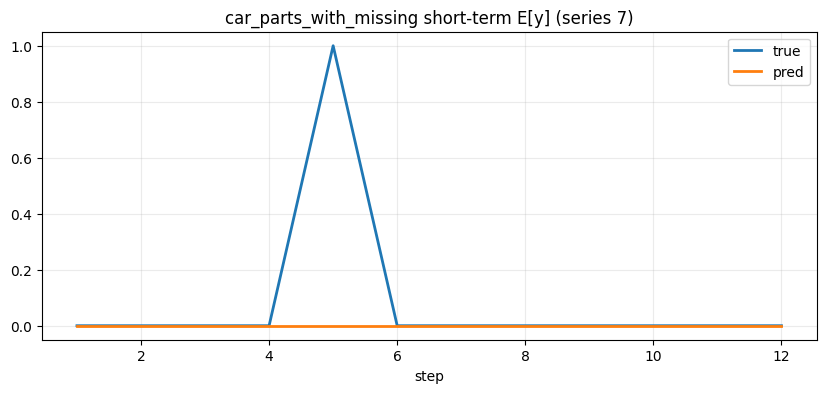

Evaluated: 34, skipped: 16
Mean relL2: 1.093270  Median: 0.971340


In [22]:
if two_model is None:
    print("Skipping evaluation: magnitude model unavailable.")
else:
    horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
    n_total = len(dataset.hf_dataset)
    errors, naive_errors, skipped, plotted = [], [], [], False
    from src.nested_kriging import _linear_impute

    for idx in _eval_indices(n_total):
        tr = _train(idx);  va = _val(idx)
        extra = va[len(tr):]
        if len(tr) < CONTEXT_LENGTH or len(extra) < horizon_length:
            skipped.append((idx, "too short")); continue
        pos = tr[np.isfinite(tr) & (tr > 0)]
        if len(pos) == 0: skipped.append((idx, "no positive train values")); continue
        scale = max(float(np.std(pos)), 1e-6)

        query_norm = _linear_impute(tr[-CONTEXT_LENGTH:]) / scale
        # E[y] in normalised units; multiply by scale to get original units
        E_y_norm = two_model.predict(query_norm)          # (H,)
        E_y = E_y_norm * scale

        true_h = extra[:horizon_length]
        obs_h = np.isfinite(true_h) & (true_h >= 0)
        if not obs_h.any(): skipped.append((idx, "no observed val-extra")); continue
        _ins = tr[np.isfinite(tr)]
        errors.append(_mase(true_h[obs_h], E_y[:horizon_length][obs_h], _ins, _sp))
        naive_errors.append(_mase(true_h[obs_h], _seasonal_naive(_ins, horizon_length, _sp)[obs_h], _ins, _sp))

        if (not EVALUATE_ALL_SERIES and idx == SERIES_INDEX) or (EVALUATE_ALL_SERIES and not plotted):
            _plot(true_h, E_y[:horizon_length],
                  title=f"{DATASET_NAME} short-term E[y] (series {idx})")
            plotted = True

    if errors:
        a = np.asarray(errors, float)
        print(f"Evaluated: {len(errors)}, skipped: {len(skipped)}")
        _n = np.asarray(naive_errors, float)
        print(f"Mean  MASE: {float(np.nanmean(a)):.4f}  Median: {float(np.nanmedian(a)):.4f}  (s-naive: {float(np.nanmean(_n)):.4f})")
    else:
        print("No short-term forecasts evaluated."); [print(" ", s) for s in skipped]
short_errors = list(errors) if 'errors' in vars() else []
short_naive_errors = list(naive_errors) if 'naive_errors' in vars() else []


## Re-Fit Both Models on Validation Split

In [23]:
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
print("Collecting validation series …")
val_raw = []
for i, entry in enumerate(dataset.validation_dataset):
    if i >= MAX_SERIES: break
    val_raw.append(np.asarray(entry["target"], dtype=float).reshape(-1))

print("Pooling validation intermittent windows …")
ind_ctx_v, ind_lab_v, mag_ctx_v, mag_log_v, _, _ = pool_intermittent_windows(
    val_raw,
    context_length=CONTEXT_LENGTH, horizon_length=horizon_length,
    stride=horizon_length, max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    min_observed_fraction=MIN_OBSERVED_FRACTION, rng=rng,
)
print(f"  Indicator: {ind_ctx_v.shape[0]} windows  Magnitude: {mag_ctx_v.shape[0]} windows")

ell_ind_v = fit_bernoulli_lengthscale_field(
    ind_ctx_v, ind_lab_v, block_size_l1=BLOCK_SIZE_L1_IND,
    amplitude=AMPLITUDE_IND, log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    n_iter_laplace=N_ITER_LAPLACE, rng=rng,
)
clf_v = BernoulliKrigingClassifier(
    ell_ind_v, block_size=BLOCK_SIZE_L2_IND, max_blocks=MAX_BLOCKS_IND,
    amplitude=AMPLITUDE_IND, n_iter_laplace=N_ITER_LAPLACE, rng=rng,
).fit(ind_ctx_v, ind_lab_v)

if mag_ctx_v.shape[0] >= 5:
    ell_mag_v = fit_gibbs_lengthscale_field(
        mag_ctx_v, mag_log_v, block_size_l1=BLOCK_SIZE_L1_MAG,
        sigma_n=SIGMA_N_MAG, amplitude=AMPLITUDE_MAG, rng=rng,
    )
    mag_v = NestedKrigingForecaster(
        ell_mag_v, block_size=BLOCK_SIZE_L2_MAG, max_blocks=MAX_BLOCKS_MAG,
        sigma_n=SIGMA_N_L2_MAG, amplitude=AMPLITUDE_MAG, rng=rng,
    ).fit(mag_ctx_v, mag_log_v)
    two_model_val = TwoModelIntermittentForecaster(indicator=clf_v, magnitude=mag_v)
else:
    print("WARNING: validation magnitude pool < 5 windows — using train model.")
    two_model_val = two_model
print("Validation model ready.")

Pooling validation intermittent windows …
  Indicator: 324 windows  Magnitude: 181 windows
Validation model ready.


## Long-Term Evaluation: test window 0

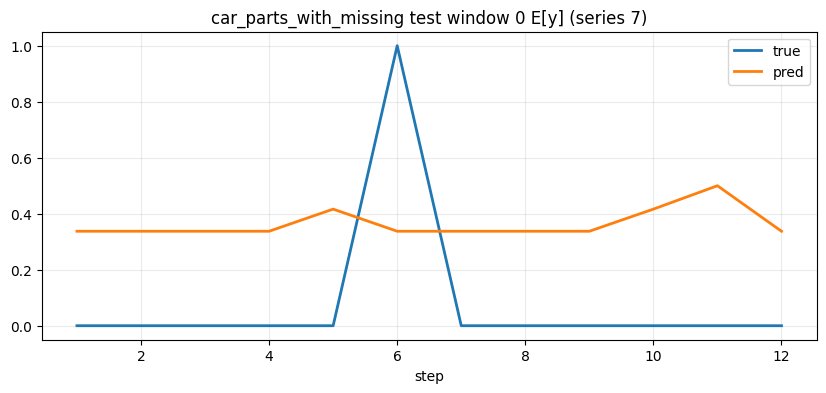

Evaluated: 39, skipped: 11
Mean relL2: 56301739.237285  Median: 0.999998


In [24]:
if two_model_val is None:
    print("Skipping: two-model forecaster unavailable.")
else:
    horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
    n_total = len(dataset.hf_dataset)
    errors, naive_errors, skipped, plotted = [], [], [], False
    from src.nested_kriging import _linear_impute

    for idx in _eval_indices(n_total):
        va = _val(idx)
        pos = va[np.isfinite(va) & (va > 0)]
        if len(pos) == 0: skipped.append((idx, "no positive val values")); continue
        scale = max(float(np.std(pos)), 1e-6)
        if len(va) < CONTEXT_LENGTH: skipped.append((idx, "val too short")); continue

        _ins_long = va[np.isfinite(va)]
        _n_wins = dataset.windows if MAX_TEST_WINDOWS is None else min(MAX_TEST_WINDOWS, dataset.windows)
        _any_win = False
        for _w in range(_n_wins):
            try: ctx_e, lbl_e = _test(idx, _w)
            except IndexError: continue
            if len(ctx_e) < CONTEXT_LENGTH or len(lbl_e) < horizon_length: continue
            query_norm = _linear_impute(ctx_e[-CONTEXT_LENGTH:]) / scale
            E_y_norm = two_model_val.predict(query_norm)
            E_y = E_y_norm * scale
            true_h = lbl_e[:horizon_length]
            obs_h = np.isfinite(true_h) & (true_h >= 0)
            if not obs_h.any(): continue
            errors.append(_mase(true_h[obs_h], E_y[:horizon_length][obs_h], _ins_long, _sp))
            naive_errors.append(_mase(true_h[obs_h], _seasonal_naive(_ins_long, horizon_length, _sp)[obs_h], _ins_long, _sp))
            _any_win = True
            if (not EVALUATE_ALL_SERIES and idx == SERIES_INDEX) or (EVALUATE_ALL_SERIES and not plotted):
                _plot(true_h, E_y[:horizon_length],
                      title=f"{DATASET_NAME} test w{_w} E[y] (series {idx})")
                plotted = True
        if not _any_win: skipped.append((idx, "no valid test windows")); continue

    if errors:
        a = np.asarray(errors, float)
        print(f"Evaluated: {len(errors)}, skipped: {len(skipped)}")
        _n = np.asarray(naive_errors, float)
        print(f"Mean  MASE: {float(np.nanmean(a)):.4f}  Median: {float(np.nanmedian(a)):.4f}  (s-naive: {float(np.nanmean(_n)):.4f})")
    else:
        print("No test forecasts evaluated."); [print(" ", s) for s in skipped]

## Inspect Demand Rates P(z=1|x*) from the Indicator Model

In [25]:
# ── Inspect demand rates from the indicator model ─────────────────
print("Sample P(demand > 0 | x*) for 5 validation-end contexts of series", SERIES_INDEX)
from src.nested_kriging import _linear_impute
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
va = _val(SERIES_INDEX)
pos = va[np.isfinite(va) & (va > 0)]
scale = max(float(np.std(pos)), 1e-6) if len(pos) > 0 else 1.0
n_inspect = min(5, len(va) // CONTEXT_LENGTH)
for i in range(n_inspect):
    end = (i + 1) * CONTEXT_LENGTH
    if end + horizon_length > len(va): break
    q_norm = _linear_impute(va[end - CONTEXT_LENGTH: end]) / scale
    p_z = clf_v.predict_proba(q_norm)    # (H,)
    print(f"  context ending at t={end}: P(z=1) per step = {p_z.round(3)}")

Sample P(demand > 0 | x*) for 5 validation-end contexts of series 0
  context ending at t=15: P(z=1) per step = [0.22  0.164 0.194 0.201 0.238 0.153 0.235 0.202 0.205 0.179 0.2   0.241]


In [26]:
# ── Export model state for cross-dataset nested kriging layer ────────────────
from pathlib import Path
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), ".."))

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

safe_name = DATASET_NAME.replace("/", "__")
save_path = models_dir / f"{safe_name}.npz"
if two_model is not None and two_model.magnitude is not None:
    two_model.magnitude.save_state(save_path, dataset_name=DATASET_NAME)
    print(f"Saved magnitude model state → {save_path}  "
          f"({len(two_model.magnitude._fitted_blocks)} blocks)")
else:
    print("Skipped: two_model or magnitude not available.")


Saved magnitude model state → ../models/car_parts_with_missing.npz  (2 blocks)


In [ ]:
# ── Save metrics and hyperparameters to JSON ────────────────────────────────
import json as _nk_json
import numpy as _nk_np
_nk_results_dir = REPO_ROOT / "experiments" / "results"
_nk_results_dir.mkdir(parents=True, exist_ok=True)

_nk_hyperparams = {
    "DATASET_NAME":            DATASET_NAME,
    "TERM":                    TERM,
    "CONTEXT_LENGTH":          CONTEXT_LENGTH,
    "HORIZON_LENGTH":          HORIZON_LENGTH,
    "MIN_OBSERVED_FRACTION":   MIN_OBSERVED_FRACTION,
    "MAX_SERIES":              MAX_SERIES,
    "MAX_WINDOWS_PER_SERIES":  MAX_WINDOWS_PER_SERIES,
    "EVALUATE_ALL_SERIES":     EVALUATE_ALL_SERIES,
    "EVAL_SERIES_LIMIT":       EVAL_SERIES_LIMIT,
    "indicator_model": {
        "BLOCK_SIZE_L1_IND":   BLOCK_SIZE_L1_IND,
        "AMPLITUDE_IND":       AMPLITUDE_IND,
        "LOG_ELL_LO":          LOG_ELL_LO,
        "LOG_ELL_HI":          LOG_ELL_HI,
        "N_ITER_LAPLACE":      N_ITER_LAPLACE,
        "META_AMPLITUDE_IND":  META_AMPLITUDE_IND,
        "META_BANDWIDTH_IND":  META_BANDWIDTH_IND,
        "BLOCK_SIZE_L2_IND":   BLOCK_SIZE_L2_IND,
        "MAX_BLOCKS_IND":      MAX_BLOCKS_IND,
    },
    "magnitude_model": {
        "BLOCK_SIZE_L1_MAG":   BLOCK_SIZE_L1_MAG,
        "SIGMA_N_MAG":         SIGMA_N_MAG,
        "AMPLITUDE_MAG":       AMPLITUDE_MAG,
        "META_AMPLITUDE_MAG":  META_AMPLITUDE_MAG,
        "META_BANDWIDTH_MAG":  META_BANDWIDTH_MAG,
        "BLOCK_SIZE_L2_MAG":   BLOCK_SIZE_L2_MAG,
        "MAX_BLOCKS_MAG":      MAX_BLOCKS_MAG,
        "SIGMA_N_L2_MAG":      SIGMA_N_L2_MAG,
    },
}

_nk_short = [float(e) for e in short_errors] if 'short_errors' in vars() and short_errors else []
_nk_test  = [float(e) for e in errors]       if 'errors'       in vars() and errors       else []

_nk_short_n = [float(e) for e in short_naive_errors] if 'short_naive_errors' in vars() and short_naive_errors else []
_nk_test_n  = [float(e) for e in test_naive_errors]  if 'test_naive_errors'  in vars() and test_naive_errors  else []

_nk_out = {
    "hyperparameters":    _nk_hyperparams,
    "short_term_MASE":  _nk_short,
    "test_MASE":        _nk_test,
    "metrics": {
        "short_mean_MASE":   float(_nk_np.nanmean(_nk_short))   if _nk_short else None,
        "short_median_MASE": float(_nk_np.nanmedian(_nk_short)) if _nk_short else None,
        "short_n_evaluated":  len(_nk_short),
        "test_mean_MASE":    float(_nk_np.nanmean(_nk_test))    if _nk_test  else None,
        "test_median_MASE":  float(_nk_np.nanmedian(_nk_test))  if _nk_test  else None,
        "test_n_evaluated":   len(_nk_test),
        "test_mean_s_naive_MASE":    float(_nk_np.nanmean(_nk_test_n))    if '_nk_test_n' in dir() and _nk_test_n  else None,
    },
}

_nk_fpath = _nk_results_dir / "car_parts_with_missing.json"
with open(_nk_fpath, "w") as _nk_f:
    _nk_json.dump(_nk_out, _nk_f, indent=2)
print(f"Results saved → {_nk_fpath}")
